# Musterlösung: Phasenfarben und Signalanteile

Diese Fassung enthält die ausgefüllten Rechenschritte und Kurzantworten zur Aufgabenfassung `experiment.ipynb`. Datenimport, Phasen-Magnitude-Blend und pixelweise Signalanteile werden auf den mitgelieferten Dual-Echo-Daten ausgeführt. Die B₀-Frequenzkarte verwendet die äußeren Triple-Echos ohne Maske.

Die Farbmischung verwendet gemessene Phasen, die Helligkeit die Magnitude. Ein für diesen Beispielscan vorgegebener globaler Phasenbezug setzt die Bedeutung von Rot und Blau fest. Er korrigiert keine räumlichen Feldunterschiede. Die Signalanteile sind Modellschätzungen, keine gemessenen Stoffkonzentrationen.

Führen Sie die Zellen der Reihe nach aus. Alle Abbildungen und Zahlen stehen in den Zellenausgaben und werden mit dem Notebook gespeichert.

## Vorbereitung

Führen Sie bei Bedarf die Installationszelle aus. Starten Sie danach den Kernel neu und führen Sie anschließend die **Importzelle darunter** aus. Sind die Bibliotheken bereits installiert, beginnen Sie direkt bei den Importen.

In [1]:
%pip install -r requirements-jupyterhub.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import numpy as np
import pydicom
import matplotlib.pyplot as plt
import mrt_hilfen as mh

print("Bibliotheken geladen.")

Bibliotheken geladen.


## Daten laden und verstehen

| Begriff | Bedeutung in diesem Notebook |
| --- | --- |
| Echo / TE | Ein Bild wird zu einer bestimmten Echozeit TE aufgenommen. |
| Magnitude | Die Stärke des gemessenen Signals, dargestellt als Helligkeit. |
| Phase | Die Winkellage des Signals; hier nach dem Import in Radiant (rad). |
| IP / OP | Wasser und Fett schwingen ungefähr gleichphasig / gegenphasig. |
| DICOM-Metadaten | Begleitinformationen wie Echozeit, Bildtyp und Bildgeometrie. |

Die erste Datei legt die Schichtebene fest. Der Katalog sucht dazu passende Bilder. **Echonummer und IP/OP sind nicht dasselbe:** Entscheidend sind die tatsächliche TE und der Wasser-Fett-Frequenzabstand.

In [3]:
datenordner = "daten/beispiel"
referenzdatei = Path(datenordner) / "wasser_oel_dual_echo2_magnitude.dcm"
phasenreferenz_datei = Path(datenordner) / "phasenreferenz.json"

dicom = pydicom.dcmread(referenzdatei)
katalog = mh.katalog(datenordner, referenz=dicom)
auswahl = mh.echo_auswahl(katalog, "T1W_FFE dual echo")

Beim Beispiel ist das frühe Echo näherungsweise OP, das späte IP. Lassen Sie die Voreinstellung für den ersten Durchlauf stehen. Nach einer Änderung der Auswahl müssen Sie die folgende Zelle und alle nachfolgenden Zellen erneut ausführen.

Die Hilfsdatei prüft, ob die Bilder zur selben Aufnahme und Schichtebene gehören. Sie berechnet die Aufgaben dieses Notebooks nicht für Sie.

In [4]:
op, ip, meta_op, meta_ip = mh.lade_paar(auswahl)
phase_op, meta_phase_op = mh.phase_zu_magnitude(katalog, meta_op)
phase_ip, meta_phase_ip = mh.phase_zu_magnitude(katalog, meta_ip)
phasenreferenz_rad = mh.phasenreferenz_laden(
    phasenreferenz_datei, [meta_op, meta_ip, meta_phase_op, meta_phase_ip])

print("Bildform [Zeilen, Spalten]:", ip.shape)
print("TE OP / IP [ms]:", meta_op["echozeit_ms"], meta_ip["echozeit_ms"])
print("Einheit der Phasen:", meta_phase_op["einheit"], meta_phase_ip["einheit"])
print("Vorgegebener globaler Phasenbezug [rad]:", phasenreferenz_rad)

T1W_FFE dual echo | TE 6.901 / 13.8 ms | eine Ebene, 512 × 512 Pixel
Bildform [Zeilen, Spalten]: (512, 512)
TE OP / IP [ms]: 6.901 13.8
Einheit der Phasen: rad rad
Vorgegebener globaler Phasenbezug [rad]: -1.1828022012291726


### Magnitude und Phase vergleichen

Führen Sie die folgenden vier Darstellungszellen einzeln aus. **Jedes Bild erhält eine eigene Abbildung.** Vergleichen Sie jeweils dieselben Bildorte.

Die Magnitudenbilder verwenden dieselbe Grauwertskala, die Phasenbilder dieselbe Winkelskala. Helligkeit ist keine Wasser-/Fett-Kennzeichnung. Die Phase im signalarmen Hintergrund ist unzuverlässig.

**IP-Magnitude** · Signalstärke beim näherungsweise gleichphasigen Echo.

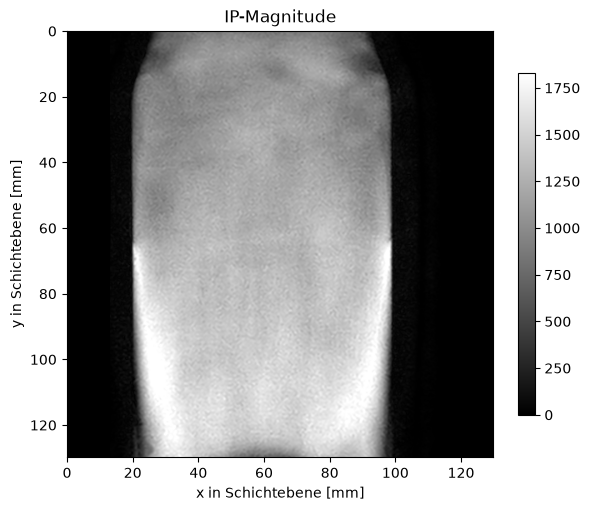

In [5]:
signalgrenze = mh.fenster(ip, op)[1]
fig_ip_magnitude = mh.bild(ip, "IP-Magnitude", meta_ip, (0, signalgrenze))

**OP-Magnitude** · Dieselbe Grauwertskala wie beim IP-Bild. Achten Sie auf Signalverluste.

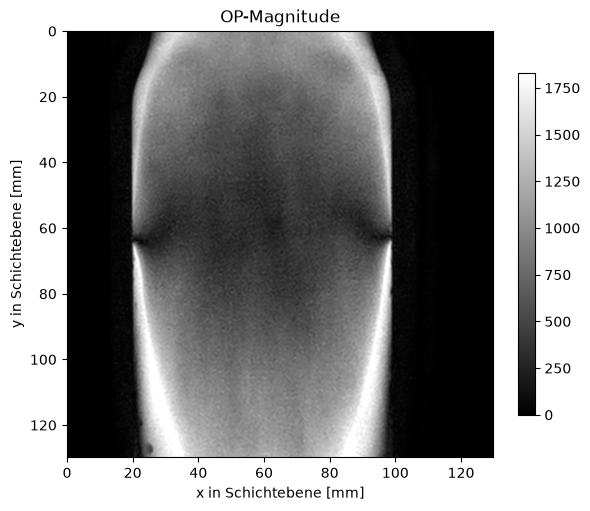

In [6]:
fig_op_magnitude = mh.bild(op, "OP-Magnitude", meta_op, (0, signalgrenze))

**IP-Phase** · Die Farbe zeigt den Signalwinkel in Radiant.

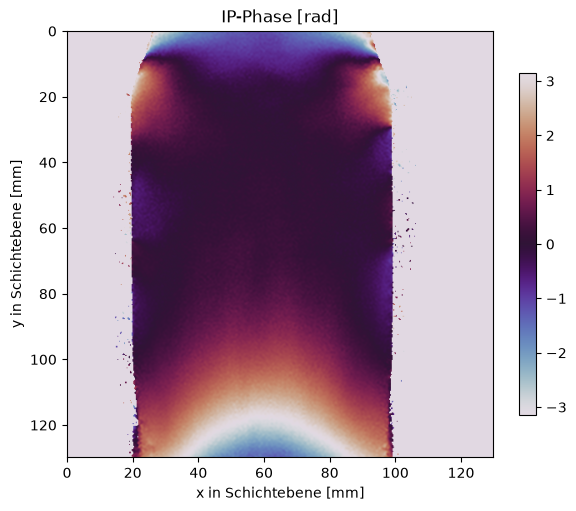

In [7]:
fig_ip_phase = mh.bild(phase_ip, "IP-Phase [rad]", meta_phase_ip, (-np.pi, np.pi), "twilight")

**OP-Phase** · Dieselbe Winkelskala wie beim IP-Phasenbild.

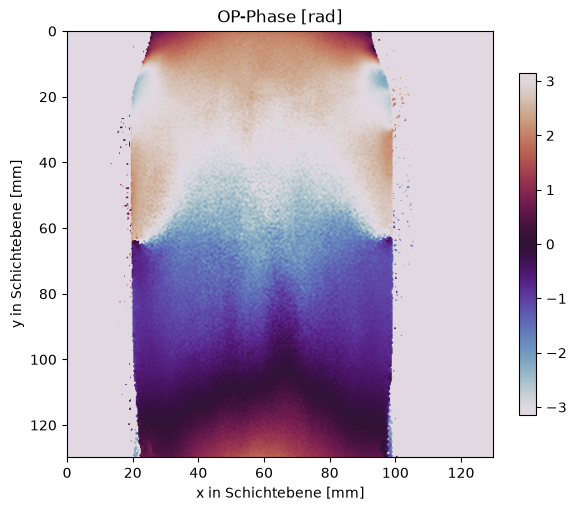

In [8]:
fig_op_phase = mh.bild(phase_op, "OP-Phase [rad]", meta_phase_op, (-np.pi, np.pi), "twilight")

## Physikalische Grundlage

**IP bedeutet nicht „nur Wasser“.** Im idealen Modell addieren sich beide Signale gleichphasig. Bei OP zeigt das Fettsignal in die entgegengesetzte Richtung:

$$S_\mathrm{IP}=W+F,\qquad S_\mathrm{OP}=W-F.$$

Dabei sind $W$ und $F$ Wasser- und Fett-/Ölsignal, keine Flüssigkeitsmengen. Diese Gleichungen setzen passende Echozeiten und eine korrigierte Hintergrundphase voraus. Ein Magnitudenbild zeigt nur den Betrag: $M_\mathrm{OP}=|W-F|$. Es verliert damit das Vorzeichen. Deshalb vergleichen wir zusätzlich die Phasen.

Für den Beispielscan ist ein **globaler Phasenbezug** vorgegeben, der an bekanntem Wasser bestimmt wurde. Die Datei `phasenreferenz.json` gehört genau zu den geladenen vier Bildern; die Zuordnung wird beim Laden geprüft. Es wird keine feste Lage von Wasser oder Öl im Bild angenommen.

Die Beispiel-Echozeiten sind nur näherungsweise IP und OP. Die vorbereitete Kontrolle berechnet die chemischen Umdrehungen aus TE und der Skriptannahme von 3,5 ppm. Eine ganze Umdrehungszahl passt zu IP, eine halbe zu OP. Das ist eine Modellprüfung, keine Spektralmessung.

In [9]:
chemie_hz = 3.5 * meta_ip["referenz_mhz"]  # Skriptannahme: ppm × MHz = Hz
umdrehungen = np.array([meta_op["echozeit_ms"], meta_ip["echozeit_ms"]]) * chemie_hz / 1000
print("Chemische Umdrehungen OP / IP:", umdrehungen)

Chemische Umdrehungen OP / IP: [1.54315755 3.08586787]


### Welche Pixel sind auswertbar?

Eine automatische **Signalmaske** schließt schwaches Signal aus. Ein Pixel ist nur gültig, wenn beide Echos genügend Signal und endliche Werte besitzen. Die Schwelle beträgt jeweils 15 % des 99. Perzentils; sie ist eine einfache Heuristik.

Die Maske wird bereitgestellt. Außerhalb der Maske steht in den Rechenarrays `NaN`: „kein auswertbarer Zahlenwert“. Sie müssen keine Bildbereiche von Hand auswählen.

In [10]:
signal_ip = np.isfinite(ip) & (ip > 0.15 * np.percentile(ip, 99))
maske = (signal_ip & np.isfinite(op) & np.isfinite(phase_ip) & np.isfinite(phase_op)
         & (op > 0.15 * np.percentile(op, 99)))
if not maske.any():
    raise ValueError("Kein gemeinsamer signalstarker Bereich in beiden Echos.")
ip_signal = np.where(maske, ip, np.nan)
op_signal = np.where(maske, op, np.nan)
print("Auswertbare Pixel:", int(maske.sum()))

Auswertbare Pixel: 153169


## 12d · Phase als Farbe, Magnitude als Helligkeit

### Aufgabe 1: Die relative Phase berechnen

Ziehen Sie von der OP-Phase die IP-Phase und den vorgegebenen Phasenbezug ab. Winkel wiederholen sich nach $2\pi$. Deshalb wird die Differenz auf den Bereich von $-\pi$ bis $\pi$ zurückgeführt:

$$\Delta\phi=\arg\{\exp[i(\phi_\mathrm{OP}-\phi_\mathrm{IP}-\phi_\mathrm{ref})]\}.$$

**Python-Hilfe:** `np.angle(z)` liefert den Winkel einer komplexen Zahl, `np.exp(...)` die Exponentialfunktion; `1j` ist die imaginäre Einheit. Ergänzen Sie die eine Rechenzeile.

In [11]:
delta_phase = np.angle(np.exp(1j * (phase_op - phase_ip - phasenreferenz_rad)))

### Aufgabe 2: Farbe und Helligkeit zusammensetzen

Berechnen Sie zwei **Farbgewichte**: $r=(1-\cos\Delta\phi)/2$ und $b=1-r$. Bei gleicher Phase wird das Bild blau, bei entgegengesetzter Phase rot.

Die Helligkeit $h$ ist die IP-Magnitude geteilt durch `signalgrenze`. Begrenzen Sie **nur diese Anzeigegröße** mit `np.clip(..., 0, 1)`. Multiplizieren Sie dann das rote bzw. blaue Gewicht mit $h$:

$$\mathrm{RGB}=(h\,r,\;0,\;h\,b).$$

Ergänzen Sie die fünf Ausdrücke. Das Zusammensetzen der Farbkanäle und die Darstellung sind vorbereitet.

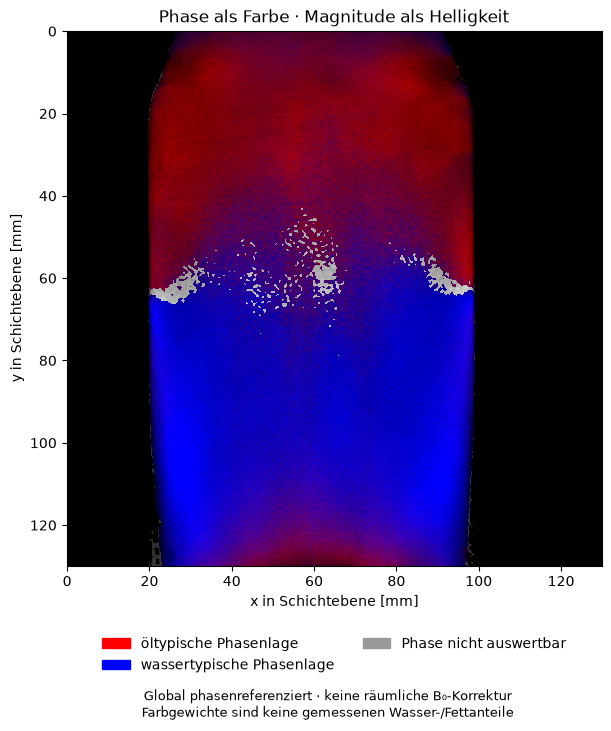

In [12]:
oelgewicht = (1 - np.cos(delta_phase)) / 2
wassergewicht = 1 - oelgewicht
helligkeit = np.clip(ip / signalgrenze, 0, 1)
rot = helligkeit * oelgewicht
blau = helligkeit * wassergewicht

rgb = np.stack((rot, np.zeros_like(rot), blau), axis=-1)
rgb[~maske] = 0
# IP-Signal, aber unzuverlässige Phase: grau statt einer Wasser-/Ölfarbe.
grau = signal_ip & ~maske
rgb[grau] = helligkeit[grau, None]
fig_farbe = mh.phasenblend_anzeigen(rgb, meta_ip)

### So lesen Sie das Farbbild

| Farbe | Aussage |
| --- | --- |
| Blau | Die relative Phase ist wasserähnlich. |
| Rot | Die relative Phase ist ölähnlich. |
| Violett | Die Phase liegt dazwischen; das allein beweist keine Mischung. |
| Grau | IP-Signal ist vorhanden, die Phase ist hier nicht auswertbar. |
| Schwarz | Zu wenig IP-Signal. |

**Ein Farbgewicht ist noch kein Fett-Signalanteil.** Dafür benötigen Sie im nächsten Schritt zusätzlich die Magnituden beider Echos.

Der vorgegebene Phasenbezug korrigiert nur einen gemeinsamen Offset, keine räumlichen B₀-Unterschiede. Auch Feldabweichungen, nicht ideale Echozeiten oder Bewegung können die Farben verändern. Die Rechnung hängt nicht von „oben“ oder „unten“ im Bild ab.

## 13 · Wasser-/Fett-Signalanteile pro Pixel

### Aufgabe 3: Vom Blend zur näherungsweisen Signalaufteilung

Nutzen Sie die relative Phase, um eine **vorzeichenbehaftete OP-Komponente** zu bilden:

$$D=M_\mathrm{OP}\cos\Delta\phi.$$

Daraus folgen im vereinfachten Modell:

$$\widehat W=\frac{M_\mathrm{IP}+D}{2},\qquad
\widehat F=\frac{M_\mathrm{IP}-D}{2},\qquad
p_F=100\,\frac{\widehat F}{\widehat W+\widehat F}.$$

Berechnen Sie die vier Größen mit `ip_signal` und `op_signal`. Die Rechnung erfolgt **für jedes gültige Pixel**, nicht als Mittelwert über einen ausgewählten Bildbereich. Die Hüte kennzeichnen Schätzwerte: Hier wird nur der globale Phasenbezug berücksichtigt; die Voraussetzungen einer vollständigen Dixon-Rekonstruktion sind nicht erfüllt.

Lassen Sie negative Signale sowie Prozentwerte außerhalb von 0 bis 100 stehen. Solche Werte zeigen Grenzen des Modells und dürfen nicht durch Beträge oder Abschneiden verborgen werden.

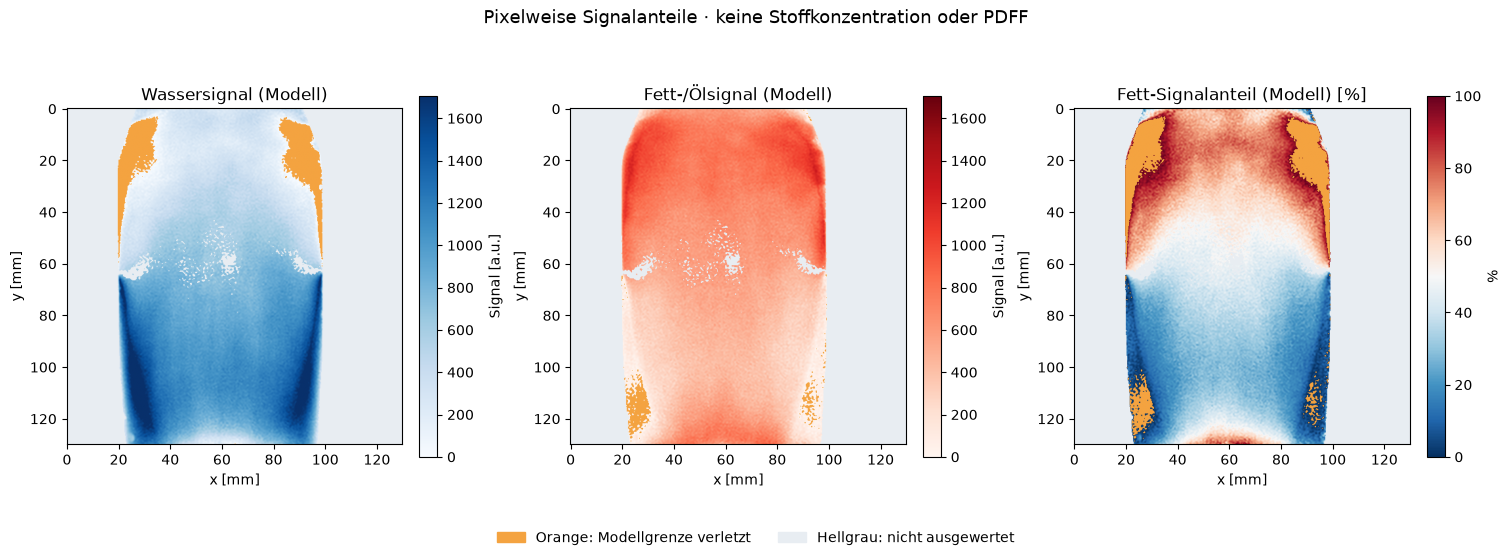

In [13]:
differenz = op_signal * np.cos(delta_phase)
wasser = (ip_signal + differenz) / 2
fett = (ip_signal - differenz) / 2
fett_signal_prozent = 100 * fett / (wasser + fett)

fig_signalanteile = mh.signalanteile_anzeigen(wasser, fett, fett_signal_prozent, maske, meta_ip)

### Ergebnisse prüfen

Die ersten beiden Karten zeigen die geschätzten Wasser- und Fett-/Ölsignale. Die dritte zeigt den Fett-Signalanteil in Prozent. **Orange** markiert negative Signale oder Prozentwerte außerhalb von 0 bis 100; **Hellgrau** nicht ausgewertete Pixel.

Die folgende Kontrolle prüft Form, Wertebereiche der Anzeige und die Beziehung Wasser + Fett = IP-Signal. Sie gibt außerdem den Anteil der Pixel mit einer Modellverletzung aus. Dieser Diagnosewert ist kein mittlerer Fettanteil der Flasche.

In [14]:
assert delta_phase.shape == ip.shape
assert rgb.shape == (*ip.shape, 3)
assert np.isfinite(rgb).all() and np.all((rgb >= 0) & (rgb <= 1))
np.testing.assert_allclose((oelgewicht + wassergewicht)[maske], 1)
np.testing.assert_allclose((wasser + fett)[maske], ip[maske])
assert np.isfinite(fett_signal_prozent[maske]).all()
assert np.isnan(fett_signal_prozent[~maske]).all()
modellverletzung = maske & ((wasser < 0) | (fett < 0))
modellverletzung_prozent = 100 * modellverletzung.sum() / maske.sum()
print("Gültige Pixel:", int(maske.sum()))
print("Davon Pixel mit Modellverletzung [%]:", float(modellverletzung_prozent))

Gültige Pixel: 153169
Davon Pixel mit Modellverletzung [%]: 8.208580065156788


### Kurzantworten der Musterlösung

1. Im IP-Bild addieren sich Wasser- und Fettsignal. Auch Öl allein kann deshalb eine große Magnitude haben. IP ist kein Wasserbild.
2. `oelgewicht` hängt nur von der relativen Phase ab und steuert die rote Farbe. `fett_signal_prozent` verwendet zusätzlich beide Magnituden und eine näherungsweise vorzeichenbehaftete OP-Komponente. Die beiden Größen beschreiben unterschiedliche Dinge.
3. Der Phasenbezug korrigiert keine räumliche Hintergrundphase. Nicht ideale Echozeiten, Relaxation, Rauschen und Partialvolumen verändern die geschätzten Signale. Die Prozentkarte ist keine validierte Protonendichte-Fettfraktion (PDFF) und kein Volumenanteil. Der rötliche untere Flaschenrand im Blend zeigt gerade, dass die Farbe nicht allein durch die Flüssigkeit bestimmt wird.

## 14 · B₀-Karte aus der Triple-Echo-Aufnahme

Wir vergleichen **Echo 3 mit Echo 1**. Wenn sich die chemische Phasenentwicklung um eine ganze Anzahl Umdrehungen weiterbewegt hat, ist die relative Phase wieder ungefähr null. Die absolute Phase des dritten Bildes muss nicht null sein. Lokale Feldabweichungen erzeugen eine zusätzliche Phasendifferenz; daraus wird die Frequenzabweichung berechnet.

Das Laden ist vorbereitet. Verwenden Sie die äußeren Phasenbilder derselben Triple-Echo-Aufnahme. Die tatsächlichen Echozeiten werden aus DICOM gelesen.

In [15]:
b0_auswahl = mh.echo_auswahl(katalog, "T1W_FFE triple echo", modus="b0")

In [16]:
b0_phase_1, b0_phase_3, b0_meta_1, b0_meta_3 = mh.lade_paar(b0_auswahl)
print("TE Echo 1 / Echo 3 [ms]:", b0_meta_1["echozeit_ms"], b0_meta_3["echozeit_ms"])
b0_chemie_hz = 3.5 * b0_meta_1["referenz_mhz"]  # Skriptannahme
print("Chemische Umdrehungen zwischen den Echos:",
      b0_chemie_hz * (b0_meta_3["echozeit_ms"] - b0_meta_1["echozeit_ms"]) / 1000)

T1W_FFE triple echo | TE 9.201 / 23.001 ms | eine Ebene, 512 × 512 Pixel
TE Echo 1 / Echo 3 [ms]: 9.201 23.001
Chemische Umdrehungen zwischen den Echos: 3.0858678732


### Aufgabe 4: Phasendifferenz → Frequenzabweichung → Karte

Berechnen Sie den Echoabstand in **Sekunden**, die Phasendifferenz in **Radiant** und daraus die Frequenzabweichung in **Hz**:

$$\Delta TE=(TE_3-TE_1)/1000,\qquad
\Delta\phi=\arg\{\exp[i(\phi_3-\phi_1)]\},\qquad
\Delta f=\frac{\Delta\phi}{2\pi\,\Delta TE}.$$

Ergänzen Sie die drei Rechenzeilen. Die vorbereitete Anzeige zeichnet die gesamte Schicht **ohne Maske**. Im signalarmen Hintergrund ist die Phase verrauscht; dort hat die Karte keine verlässliche Feldaussage.

Die Phasendifferenz liegt zwischen $-\pi$ und $\pi$. Ohne räumliches Entfalten ist die Frequenz daher nur modulo $1/\Delta TE$ bestimmt; Sprünge können Phasenumbrüche sein. Außerdem ist die chemische Gleichphasigkeit im Beispiel nur näherungsweise erfüllt. Die Karte ist eine einfache B₀-Darstellung in Hz, keine absolut kalibrierte Feldmessung. Das Vorzeichen folgt der Annahme $\phi=\phi_0+2\pi\,\Delta f\,TE$.

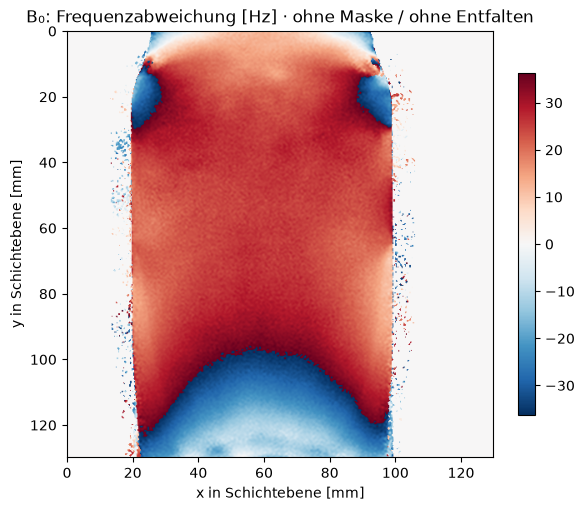

In [17]:
delta_te_b0_s = (b0_meta_3["echozeit_ms"] - b0_meta_1["echozeit_ms"]) / 1000
delta_phase_b0 = np.angle(np.exp(1j * (b0_phase_3 - b0_phase_1)))
b0_hz = delta_phase_b0 / (2 * np.pi * delta_te_b0_s)

b0_grenze_hz = 1 / (2 * delta_te_b0_s)
fig_b0 = mh.bild(b0_hz, "B₀: Frequenzabweichung [Hz] · ohne Maske / ohne Entfalten",
                 b0_meta_1, (-b0_grenze_hz, b0_grenze_hz), "RdBu_r")

## Eigene Messdaten verwenden

Laden Sie Ihre DICOM-Dateien in `daten/eigene/` hoch. Sie benötigen die Magnitude **und** die Phase beider Echos auf derselben Schichtebene. Ersetzen Sie in der vorbereiteten Ladezelle den Datenordner, den Dateipfad und die Aufnahme durch Ihre eigenen Daten.

Verwenden Sie außerdem einen passenden globalen Phasenbezug für Ihre Messung, den die Betreuung bereitstellt. Der Bezug des Beispieldatensatzes darf nicht übernommen werden; der Import prüft daher, ob Referenzdatei und Bilder zusammengehören. Ohne passenden Bezug haben die Farben keine eindeutige Wasser-/Öl-Bedeutung.

Führen Sie danach alle folgenden Zellen erneut aus. Eine gedrehte Darstellung erfordert keine andere Farbformel. Änderungen von Feld, Frequenzeinstellung oder Messung können dagegen einen neuen Phasenbezug erfordern.

Für die B₀-Aufgabe benötigen Sie zusätzlich die Phasenbilder der äußeren Triple-Echos. Wählen Sie dort Ihre Triple-Echo-Aufnahme und kontrollieren Sie den tatsächlichen Echoabstand sowie die chemische Gleichphasigkeit. Die B₀-Rechnung verwendet keinen Phasenbezug aus `phasenreferenz.json`.

### Hintergrund

Die Übung zeigt einen qualitativen Phasen-Magnitude-Blend und eine vereinfachte Signalaufteilung. Für eine belastbare komplexe Wasser-/Fett-Trennung müssen unter anderem räumliche Phasenfehler berücksichtigt werden: [Berglund et al., 2011: Two-point Dixon method with flexible echo times](https://doi.org/10.1002/mrm.22679).

Die Hilfsdatei übernimmt DICOM-Import, Skalierung, Paarprüfung und Darstellung. **Die Rechenschritte für Phase, Farbgewichte, Helligkeit und Signalanteile stehen sichtbar in Ihrem Notebook.**

Die B₀-Frequenzkarte folgt dem Zusammenhang zwischen Phasendifferenz und Echoabstand: [SDCFlows-Dokumentation](https://www.nipreps.org/sdcflows/1.4/_modules/sdcflows/workflows/fit/fieldmap.html). Hier wird bewusst die einfache, nicht räumlich entfaltete Darstellung gezeigt.

### Prüfung der Musterlösung

Die folgenden Kontrollen prüfen die Datenpaarung und die berechneten Signal- und Frequenzkarten.

In [18]:
assert len(katalog) == 20
assert b0_meta_1["aufnahme"] == b0_meta_3["aufnahme"] == "T1W_FFE triple echo"
assert b0_meta_1["gruppe"] == b0_meta_3["gruppe"]
assert mh.gleiche_geometrie(b0_meta_1, b0_meta_3)
b0_echos = sorted(m["echozeit_ms"] for m in katalog if m["gruppe"] == b0_meta_1["gruppe"] and m["komponente"] == "PHASE")
assert len(b0_echos) == 3
assert b0_meta_1["echozeit_ms"] == b0_echos[0] and b0_meta_3["echozeit_ms"] == b0_echos[-1]
assert delta_te_b0_s > 0 and b0_hz.shape == ip.shape
assert np.isfinite(b0_hz).all()  # Ganzer Bildbereich, keine NaN-Maskierung.
assert np.max(np.abs(b0_hz)) <= b0_grenze_hz + 1e-10
np.testing.assert_allclose(b0_hz * (2 * np.pi * delta_te_b0_s), delta_phase_b0)
assert ip.shape == op.shape == (512, 512)
assert meta_op["aufnahme"] == meta_ip["aufnahme"] == "T1W_FFE dual echo"
assert mh.gleiche_geometrie(meta_op, meta_ip)
assert meta_phase_op["gruppe"] == meta_op["gruppe"]
assert meta_phase_ip["gruppe"] == meta_ip["gruppe"]
np.testing.assert_allclose((wasser - fett)[maske], differenz[maske])
print("Alle Kontrollen erfolgreich. Abbildungen und Ergebnisse stehen in den Notebook-Zellen.")
plt.close("all")

Alle Kontrollen erfolgreich. Abbildungen und Ergebnisse stehen in den Notebook-Zellen.
